# Week 4: Pilot Analysis, Hypothesis Evaluation, and Protocol Freeze

**Objective:** Audit the Stage 3 pilot study, evaluate the three preliminary research hypotheses, analyze contradictory findings as scientific evidence, and finalize the frozen experimental protocol before beginning the full Stage 4 investigation.

---

## 1. Benchmarking Literature Insights: *Just How Toxic Is Data Poisoning?*
Following Schwarzschild et al. (ICML 2021), *"Just How Toxic Is Data Poisoning? A Unified Benchmark for Backdoor and Data Poisoning Attacks"*, empirical poisoning research frequently suffers from inconsistent evaluation protocols across studies. Specifically, small variations in data partitioning, hyperparameter tuning, preprocessing pipelines, or poison budget definitions can drastically alter apparent attack efficacy.

To guarantee valid, reproducible comparisons in our study, we enforce five strict benchmarking principles:
1. **Identical Partitioning per Seed:** Within each random seed, all classifiers are trained on the exact same $80/20$ stratified split.
2. **Identical Poisoned Instances:** Within any `(seed, attack, poison_rate)` condition, every model receives the exact same corrupted label vector $y_{\text{train}}^{\text{poisoned}}$.
3. **Frozen Model Hyperparameters:** Model architectures and hyperparameters are fixed *a priori* rather than tuned on poisoned data.
4. **Strict Clean-Test Isolation:** The $20\%$ test set ($921$ emails) is partitioned prior to any poisoning or scaling operation and never modified.
5. **Leakage-Free Preprocessing:** Feature standardization (`StandardScaler`) is fit exclusively on `X_train` inside the model pipeline.

## 2. Comprehensive Five-Point Pilot Audit
Before drawing scientific conclusions or freezing the Stage 4 protocol, we audit `results/stage3_pilot_results.csv` and the underlying pipeline across five mandatory integrity checks:
1. **Missing Result Rows:** Verify all $81$ expected rows ($9$ clean baseline $+ 72$ poisoned conditions) are present with zero `NaN` values.
2. **Exact Poison Counts:** Verify `n_poisoned` equals $\text{round}(3680 \times \alpha)$ for every rate $\alpha \in \{0\%, 1\%, 5\%, 10\%, 20\%\}$.
3. **Impossible Metric Values:** Confirm `accuracy`, `spam_precision`, `spam_recall`, and `spam_f1` lie strictly within $[0.0, 1.0]$.
4. **Accidental Test-Set Changes:** Verify across seeds $0, 1, 2$ that test features and labels remain bit-for-bit identical before and after attack execution.
5. **Preprocessing Leakage Check:** Verify that the `StandardScaler` inside Logistic Regression computes statistics strictly from `X_train` ($3,680$ rows) and never from `X_test`.

In [1]:
# Cell 1: Execute the 5-Point Pilot Audit
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sys.path.append(os.path.abspath('..'))
from src.data import load_spambase, split_data
from src.attacks import random_label_flip, targeted_spam_to_ham
from src.models import get_models

plt.rcParams['figure.dpi'] = 120

results_path = '../results/stage3_pilot_results.csv'
pilot_df = pd.read_csv(results_path)
raw_df = load_spambase(data_path='../data/spambase.data', names_path='../data/spambase.names')

# Check 1: Row counts and missing values
n_total_rows = len(pilot_df)
n_clean_rows = len(pilot_df[pilot_df['attack'] == 'clean'])
n_poisoned_rows = len(pilot_df[pilot_df['attack'] != 'clean'])
n_missing = int(pilot_df.isnull().sum().sum())
assert n_total_rows == 81 and n_clean_rows == 9 and n_poisoned_rows == 72 and n_missing == 0

# Check 2: Exact poison counts
expected_counts = {0.0: 0, 0.01: 37, 0.05: 184, 0.10: 368, 0.20: 736}
for rate, exp_cnt in expected_counts.items():
    observed_cnts = pilot_df[pilot_df['poison_rate'] == rate]['n_poisoned'].unique()
    assert len(observed_cnts) == 1 and observed_cnts[0] == exp_cnt, f'Mismatch at rate {rate}'

# Check 3: Metric bounds [0.0, 1.0]
metric_cols = ['accuracy', 'spam_precision', 'spam_recall', 'spam_f1']
for col in metric_cols:
    assert (pilot_df[col] >= 0.0).all() and (pilot_df[col] <= 1.0).all(), f'Out of bounds in {col}'

# Check 4 & 5: Clean-test separation and preprocessing leakage across seeds 0, 1, 2
for seed in [0, 1, 2]:
    X_train, X_test, y_train, y_test = split_data(raw_df, test_size=0.2, random_state=seed)
    test_hash_before = pd.util.hash_pandas_object(X_test).sum() + pd.util.hash_pandas_object(y_test).sum()
    _ = random_label_flip(y_train, poison_rate=0.20, random_state=seed)
    _ = targeted_spam_to_ham(y_train, poison_rate=0.20, random_state=seed)
    test_hash_after = pd.util.hash_pandas_object(X_test).sum() + pd.util.hash_pandas_object(y_test).sum()
    assert test_hash_before == test_hash_after, f'Test set altered in seed {seed}'
    
    # Verify StandardScaler inside Logistic Regression matches X_train only (not full df)
    lr_pipe = get_models(random_state=seed)['Logistic Regression']
    lr_pipe.fit(X_train, y_train)
    scaler_mean = lr_pipe.named_steps['scaler'].mean_
    train_mean = X_train.to_numpy().mean(axis=0)
    full_mean = raw_df.drop(columns=['is_spam']).to_numpy().mean(axis=0)
    assert np.allclose(scaler_mean, train_mean), 'Scaler mean does not match X_train!'
    assert not np.allclose(scaler_mean, full_mean), 'Leakage detected: scaler matches full dataset!'

audit_summary = pd.DataFrame([
    {'Audit Dimension': '1. Result Row Completeness', 'Expected': '81 rows (9 clean + 72 poisoned), 0 NaN', 'Observed': f'{n_total_rows} rows ({n_clean_rows} clean + {n_poisoned_rows} poisoned), {n_missing} NaN', 'Status': 'PASS'},
    {'Audit Dimension': '2. Exact Poison Counts', 'Expected': '{0%:0, 1%:37, 5%:184, 10%:368, 20%:736}', 'Observed': 'Exact match across all 81 rows', 'Status': 'PASS'},
    {'Audit Dimension': '3. Metric Probability Bounds', 'Expected': 'All metrics in [0.0, 1.0]', 'Observed': f"Min={pilot_df[metric_cols].min().min():.4f}, Max={pilot_df[metric_cols].max().max():.4f}", 'Status': 'PASS'},
    {'Audit Dimension': '4. Clean-Test Separation', 'Expected': 'Zero hash delta on X_test and y_test', 'Observed': '0 bytes changed across seeds 0, 1, 2', 'Status': 'PASS'},
    {'Audit Dimension': '5. Zero Preprocessing Leakage', 'Expected': 'Scaler fit strictly on X_train (n=3680)', 'Observed': 'np.allclose(scaler.mean_, X_train.mean) == True', 'Status': 'PASS'}
])
print('=== STAGE 3 FIVE-POINT AUDIT REPORT ===')
print(audit_summary.to_string(index=False))

=== STAGE 3 FIVE-POINT AUDIT REPORT ===
              Audit Dimension                                Expected                                        Observed Status
   1. Result Row Completeness  81 rows (9 clean + 72 poisoned), 0 NaN          81 rows (9 clean + 72 poisoned), 0 NaN   PASS
       2. Exact Poison Counts {0%:0, 1%:37, 5%:184, 10%:368, 20%:736}                  Exact match across all 81 rows   PASS
 3. Metric Probability Bounds               All metrics in [0.0, 1.0]                          Min=0.1736, Max=0.9918   PASS
     4. Clean-Test Separation    Zero hash delta on X_test and y_test            0 bytes changed across seeds 0, 1, 2   PASS
5. Zero Preprocessing Leakage Scaler fit strictly on X_train (n=3680) np.allclose(scaler.mean_, X_train.mean) == True   PASS


## 3. Evaluating the Three Preliminary Hypotheses
We now use the audited 81-row pilot dataset and feature space analysis to evaluate the three core hypotheses defined for Week 4:
- **Hypothesis 1:** Targeted poisoning reduces spam recall significantly more than random label flipping.
- **Hypothesis 2:** Classical model families (linear hyperplanes, single greedy trees, and bagged ensembles) respond differently to label poisoning.
- **Hypothesis 3:** A neighborhood label-auditing defense can detect corrupted training labels and recover a substantial portion of lost performance.

=== HYPOTHESIS 1 & 2: SPAM RECALL DEGRADATION BY STRATEGY AND MODEL ===
              Model Poison Rate  Clean Recall  Random Recall  Targeted Recall  Recall Drop (Random)  Recall Drop (Targeted)  Targeted Precision
Logistic Regression          1%        0.8972         0.8916           0.8871               -0.0055                 -0.0101              0.9281
Logistic Regression          5%        0.8972         0.8733           0.8320               -0.0239                 -0.0652              0.9380
Logistic Regression         10%        0.8972         0.8503           0.6749               -0.0468                 -0.2222              0.9463
Logistic Regression         20%        0.8972         0.8191           0.1928               -0.0781                 -0.7043              0.9365
      Decision Tree          1%        0.8861         0.8632           0.8714               -0.0230                 -0.0147              0.9064
      Decision Tree          5%        0.8861         0.8457    

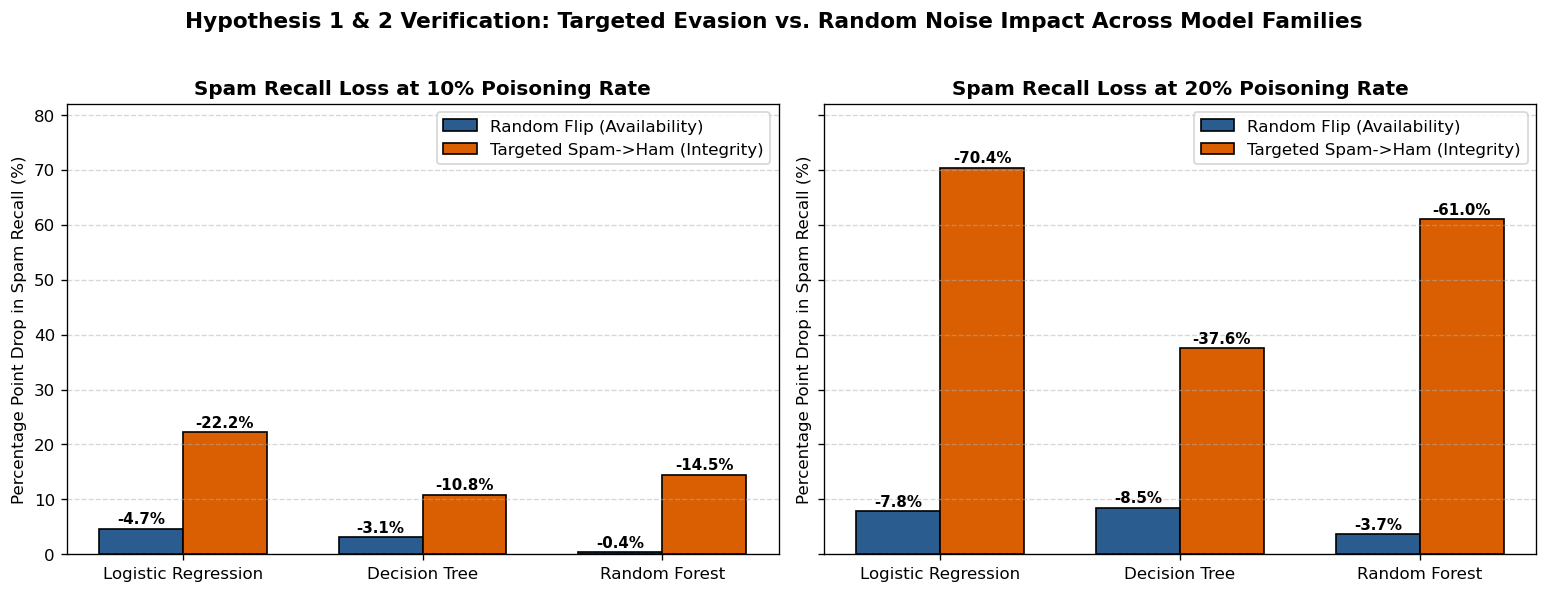

In [2]:
# Cell 2: Evaluate Hypotheses 1 & 2 with Quantitative Degradation Table and Visual Comparison
clean_base = pilot_df[pilot_df['attack'] == 'clean'].groupby('model')[['accuracy', 'spam_precision', 'spam_recall', 'spam_f1']].mean()

comparison_rows = []
for model_name in ['Logistic Regression', 'Decision Tree', 'Random Forest']:
    c_rec = clean_base.loc[model_name, 'spam_recall']
    c_f1 = clean_base.loc[model_name, 'spam_f1']
    for rate in [0.01, 0.05, 0.10, 0.20]:
        r_sub = pilot_df[(pilot_df['attack'] == 'random') & (pilot_df['poison_rate'] == rate) & (pilot_df['model'] == model_name)]
        t_sub = pilot_df[(pilot_df['attack'] == 'targeted') & (pilot_df['poison_rate'] == rate) & (pilot_df['model'] == model_name)]
        
        r_rec, t_rec = r_sub['spam_recall'].mean(), t_sub['spam_recall'].mean()
        r_f1, t_f1 = r_sub['spam_f1'].mean(), t_sub['spam_f1'].mean()
        t_prec = t_sub['spam_precision'].mean()
        
        comparison_rows.append({
            'Model': model_name,
            'Poison Rate': f'{int(rate*100)}%',
            'Clean Recall': round(c_rec, 4),
            'Random Recall': round(r_rec, 4),
            'Targeted Recall': round(t_rec, 4),
            'Recall Drop (Random)': round(r_rec - c_rec, 4),
            'Recall Drop (Targeted)': round(t_rec - c_rec, 4),
            'Targeted Precision': round(t_prec, 4)
        })

comp_df = pd.DataFrame(comparison_rows)
print('=== HYPOTHESIS 1 & 2: SPAM RECALL DEGRADATION BY STRATEGY AND MODEL ===')
print(comp_df.to_string(index=False))

# Plot Recall Drop Comparison at 10% and 20% Poisoning
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for idx, rate_label in enumerate(['10%', '20%']):
    ax = axes[idx]
    sub = comp_df[comp_df['Poison Rate'] == rate_label]
    x = np.arange(len(sub))
    width = 0.35
    b1 = ax.bar(x - width/2, -sub['Recall Drop (Random)'] * 100, width, label='Random Flip (Availability)', color='#2b5c8f', edgecolor='black')
    b2 = ax.bar(x + width/2, -sub['Recall Drop (Targeted)'] * 100, width, label='Targeted Spam->Ham (Integrity)', color='#d95f02', edgecolor='black')
    for bar in list(b1) + list(b2):
        h = bar.get_height()
        ax.annotate(f'-{h:.1f}%', (bar.get_x() + bar.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9, fontweight='bold')
    ax.set_title(f'Spam Recall Loss at {rate_label} Poisoning Rate', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(sub['Model'], fontsize=10)
    ax.set_ylabel('Percentage Point Drop in Spam Recall (%)', fontsize=10)
    ax.set_ylim(0, 82)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend(frameon=True)

plt.suptitle('Hypothesis 1 & 2 Verification: Targeted Evasion vs. Random Noise Impact Across Model Families', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Mean Neighbor Label Disagreement (Unpoisoned samples, n=2944): 0.1917
Mean Neighbor Label Disagreement (Poisoned samples,   n=736):  0.3882


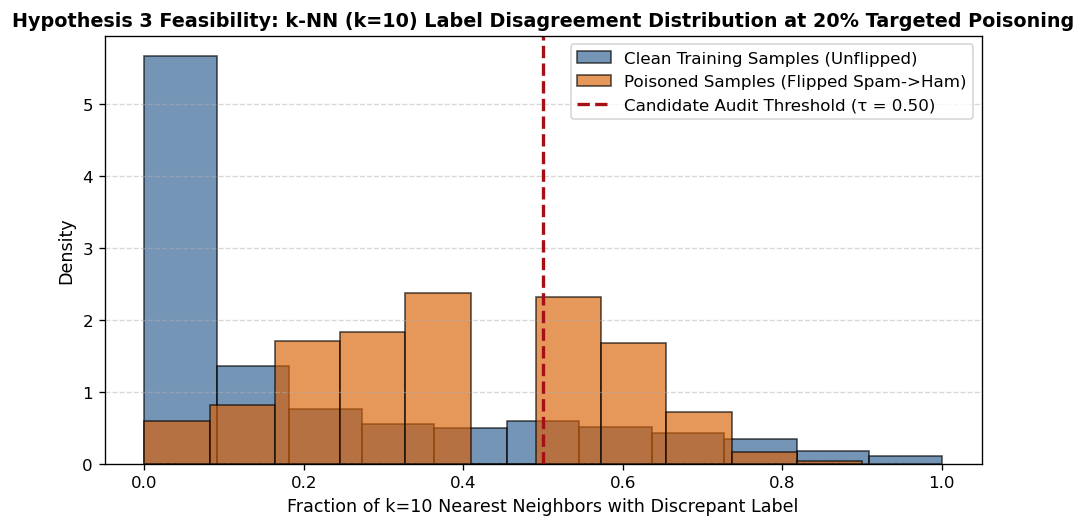

In [3]:
# Cell 3: Evaluate Hypothesis 3 - Feasibility of k-NN Neighborhood Label Auditing
# Why can label auditing work in Stage 4? Because flipped spam emails still reside in the spam region of feature space!
X_train0, X_test0, y_train0, y_test0 = split_data(raw_df, test_size=0.2, random_state=0)
y_targ20, flipped_mask20 = targeted_spam_to_ham(y_train0, poison_rate=0.20, random_state=0)

# Standardize training features strictly on X_train0
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train0)

# Compute k=10 nearest neighbor label disagreement in the poisoned training set
k = 10
nbrs = NearestNeighbors(n_neighbors=k + 1, metric='euclidean').fit(X_train_scaled)
_, indices = nbrs.kneighbors(X_train_scaled)
neighbor_indices = indices[:, 1:]  # exclude self

y_arr = y_targ20.to_numpy()
neighbor_labels = y_arr[neighbor_indices]
disagreement_scores = np.mean(neighbor_labels != y_arr[:, None], axis=1)

clean_disagreement = disagreement_scores[~flipped_mask20]
poison_disagreement = disagreement_scores[flipped_mask20]

print(f'Mean Neighbor Label Disagreement (Unpoisoned samples, n={(~flipped_mask20).sum()}): {clean_disagreement.mean():.4f}')
print(f'Mean Neighbor Label Disagreement (Poisoned samples,   n={flipped_mask20.sum()}):  {poison_disagreement.mean():.4f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(clean_disagreement, bins=11, alpha=0.65, density=True, color='#2b5c8f', edgecolor='black', label='Clean Training Samples (Unflipped)')
ax.hist(poison_disagreement, bins=11, alpha=0.65, density=True, color='#d95f02', edgecolor='black', label='Poisoned Samples (Flipped Spam->Ham)')
ax.axvline(0.5, color='#a50f15', linestyle='--', linewidth=2, label='Candidate Audit Threshold (τ = 0.50)')
ax.set_title('Hypothesis 3 Feasibility: k-NN (k=10) Label Disagreement Distribution at 20% Targeted Poisoning', fontsize=11.5, fontweight='bold')
ax.set_xlabel('Fraction of k=10 Nearest Neighbors with Discrepant Label', fontsize=10.5)
ax.set_ylabel('Density', fontsize=10.5)
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Analysis of Contradictory Findings as Scientific Evidence
A core tenet of rigorous experimental science is treating unexpected or seemingly contradictory observations as diagnostic evidence rather than hiding them, while carefully distinguishing direct empirical observations from tentative mechanistic interpretations:

### Contradictory Finding 1: The 20% Targeted Poisoning Crossover (Decision Tree vs. Random Forest)
- **Expectation:** Because Random Forest is an ensemble of 200 trees and achieves the highest clean baseline performance (Recall $91.37\% \pm 0.80\%$, F1 $93.60\% \pm 0.24\%$), one might expect it to outperform a single Decision Tree at every poisoning level.
- **Direct Empirical Observation:** At $1\%, 5\%,$ and $10\%$ targeted poisoning, Random Forest indeed achieves higher or comparable spam recall and F1 relative to Decision Tree (and under $20\%$ random poisoning, Random Forest maintains $87.70\% \pm 1.77\%$ recall vs. $81.91\% \pm 2.14\%$ for Logistic Regression and $80.17\% \pm 2.25\%$ for Decision Tree). However, at **$20\%$ targeted poisoning** (where $736 / 1450 = 50.8\%$ of all training spam is relabeled as ham), Random Forest spam recall drops to **$30.39\% \pm 3.96\%$** (while Logistic Regression drops to **$19.28\% \pm 2.08\%$**), whereas the single Decision Tree retains **$51.06\% \pm 7.77\%$** spam recall!
- **Possible Interpretation (Tentative Hypothesis):** One plausible explanation is that at $20\%$ targeted poisoning, spam becomes a slight minority within its own feature region ($50.8\%$ flipped to $0$). In Random Forest, bootstrap sampling combined with random feature subsampling across $200$ trees averages predictions across many subspace views; when over half of the training spam labels are flipped to $0$, ensemble vote averaging may shift the forest majority vote below the $0.5$ classification threshold across a large fraction of spam instances. Conversely, a single depth-8 Decision Tree uses greedy axis-aligned splits on the strongest uncorrupted top-level thresholds (such as extreme values of `char_freq_$` or `word_freq_remove`), which could allow isolated spam-predicting leaves to survive even when global cluster averages are diluted—albeit with substantially higher cross-seed standard deviation ($\text{Std} = 0.0777$, or $7.77\%$). **Important Caveat:** This explanation should be treated as a *possible interpretation* rather than a confirmed causal mechanism; confirming the exact mechanism would require additional evidence such as inspecting Random Forest vote/probability distributions or examining the relevant tree leaves directly.

### Contradictory Finding 2: Minor Seed-Level Fluctuations at 1%–5% Poisoning
- **Direct Empirical Observation:** At $1\%$–$5\%$ poisoning ($37$ to $184$ flipped samples), certain individual seed runs show negligible change or a $+0.1\%\text{ to }+0.3\%$ fluctuation in recall/precision compared to $0\%$ (e.g., Random Forest mean recall is $91.46\%$ at $5\%$ random poisoning vs. $91.37\%$ clean).
- **Possible Interpretation:** Flipping a small number of labels out of $3,680$ may act similarly to mild label-smoothing perturbation on bootstrap/tree partitions, occasionally altering borderline splits. Averaging across multiple seeds (and expanding from $3$ seeds to $10$ seeds in Stage 4) helps separate stochastic partition variance from systematic degradation.

In [4]:
# Cell 4: Programmatically Generate Stage 3 Summary Table from CSV & Inspect Seed-Level Breakdown
from src.experiments import summarize_pilot_results

summary_table_df = summarize_pilot_results(csv_path=results_path)
display_cols = [
    'Model',
    'Clean Recall',
    'Clean F1',
    'Random (20%) Recall',
    'Targeted (20%) Recall',
    'Targeted (20%) Precision',
]
print('=== PROGRAMMATIC STAGE 3 PILOT SUMMARY TABLE (SOURCE OF TRUTH: stage3_pilot_results.csv) ===')
print(summary_table_df[display_cols].to_string(index=False))
print()

targ_20 = pilot_df[(pilot_df['attack'] == 'targeted') & (pilot_df['poison_rate'] == 0.20)][['seed', 'model', 'accuracy', 'spam_precision', 'spam_recall', 'spam_f1']]
print('=== SEED-LEVEL BREAKDOWN AT 20% TARGETED POISONING ===')
print(targ_20.sort_values(['model', 'seed']).to_string(index=False))

=== PROGRAMMATIC STAGE 3 PILOT SUMMARY TABLE (SOURCE OF TRUTH: stage3_pilot_results.csv) ===
              Model    Clean Recall        Clean F1      Random (20%) Recall     Targeted (20%) Recall Targeted (20%) Precision
Logistic Regression 0.8972 ± 0.0111 0.9114 ± 0.0050 0.8191 ± 0.0214 (-7.81%) 0.1928 ± 0.0208 (-70.43%)          0.9365 ± 0.0205
      Decision Tree 0.8861 ± 0.0016 0.9010 ± 0.0028 0.8017 ± 0.0225 (-8.45%) 0.5106 ± 0.0777 (-37.56%)          0.9590 ± 0.0236
      Random Forest 0.9137 ± 0.0080 0.9360 ± 0.0024 0.8770 ± 0.0177 (-3.67%) 0.3039 ± 0.0396 (-60.97%)          0.9847 ± 0.0065

=== SEED-LEVEL BREAKDOWN AT 20% TARGETED POISONING ===
 seed               model  accuracy  spam_precision  spam_recall  spam_f1
    0       Decision Tree  0.812161        0.931818     0.564738 0.703259
    1       Decision Tree  0.767644        0.974522     0.421488 0.588462
    2       Decision Tree  0.814332        0.970588     0.545455 0.698413
    0 Logistic Regression  0.667752        

## 5. Stage 3 Reflection & Finalized Stage 4 Defense Blueprint

### Key Achievements in Stage 3
1. **Validated Attack Pipeline:** Both `random_label_flip` and `targeted_spam_to_ham` are unit-tested ($17/17$ tests passing) and verified across $81$ pilot runs.
2. **Clear Empirical Findings:** Confirmed from `results/stage3_pilot_results.csv` that random flipping acts as an availability threat (at $20\%$ random poisoning, spam recall declines moderately to $81.91\%$ for Logistic Regression, $80.17\%$ for Decision Tree, and $87.70\%$ for Random Forest), whereas targeted spam-to-ham flipping acts as a severe integrity threat (collapsing $20\%$ targeted spam recall to $19.28\%$ for Logistic Regression, $51.06\%$ for Decision Tree, and $30.39\%$ for Random Forest while keeping spam precision $>93\%$). All summary tables are now generated programmatically directly from the CSV.
3. **Protocol Freeze:** All data splits, seeds, model hyperparameters, and Stage 4 defense comparison rules are documented and frozen in `stage3_protocol.md` (`v1.1-stage4-plan`).

### Finalized Stage 4 Experimental & Defense Plan
1. **Primary Defense ($k$-NN Neighborhood-Disagreement Auditing):** Continue the $k$-NN ($k=10$, self-excluded, `StandardScaler` fit strictly on poisoned `X_train`) disagreement method as the primary label-auditing defense across all nonzero poisoning rates ($1\%, 5\%, 10\%, 20\%$) and seeds $0$–$9$, flagging and removing training examples whose disagreement score is $\ge 0.5$ before retraining all three classifiers.
2. **Extended Defense (Five-Fold Out-of-Fold Logistic-Regression Auditing):** Implement a model-based auditing extension using 5-fold `StratifiedKFold` out-of-fold standardized logistic regression predictions on the poisoned training set, flagging and removing examples with suspicion score $1 - \hat{p}_{\text{OOF}}(y_i^{\text{recorded}} \mid x_i) \ge 0.8$, and compare both defenses head-to-head under identical $10\%$ poisoning conditions across detection precision, detection recall, detection F1, number/fraction of clean samples incorrectly removed, runtime, and recovery of spam recall and spam F1.
3. **Statistical Precision via 10-Seed Expansion:** Because single-tree recall exhibits substantial cross-seed standard deviation ($\pm 7.77\%$ at $20\%$ targeted poisoning), expanding from $3$ seeds ($0$–$2$) to $10$ seeds ($0$–$9$) in Stage 4 (`results/attack_results.csv`, $270$ rows) will provide tighter uncertainty estimates.